In [8]:
import numpy as np
from tensorflow import keras

In [9]:
(x_train,y_train),(x_test,y_test)=keras.datasets.mnist.load_data()

In [10]:
x_val=x_train[-10000:]
y_val=y_train[-10000:]
x_train=x_train[:-10000]
y_train=y_train[:-10000]

In [11]:
x_train=x_train/255
x_val=x_val/255
x_test=x_test/255

In [12]:
print(x_train.shape,x_val.shape,x_test.shape)
print(x_train.max())

(50000, 28, 28) (10000, 28, 28) (10000, 28, 28)
1.0


In [14]:
model=keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128,activation="relu"),
    keras.layers.Dense(10,activation="softmax")
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(loss="sparse_categorical_crossentropy",optimizer="adam",metrics=["accuracy"])

In [17]:
history=model.fit(x_train,y_train,epochs=5,batch_size=32,validation_data=(x_val,y_val))

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9177 - loss: 0.2852 - val_accuracy: 0.9548 - val_loss: 0.1548
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9620 - loss: 0.1253 - val_accuracy: 0.9683 - val_loss: 0.1047
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9747 - loss: 0.0847 - val_accuracy: 0.9722 - val_loss: 0.0942
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9819 - loss: 0.0616 - val_accuracy: 0.9747 - val_loss: 0.0899
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9850 - loss: 0.0487 - val_accuracy: 0.9739 - val_loss: 0.0876


In [18]:
counts=np.bincount(y_train)
print(counts)

[4932 5678 4968 5101 4859 4506 4951 5175 4842 4988]


In [20]:
from sklearn.linear_model import LogisticRegression
x_train_flat=x_train.reshape(len(x_train),784)
x_val_flat=x_val.reshape(len(x_val),784)
clf=LogisticRegression(max_iter=200)
clf.fit(x_train_flat,y_train)
print(clf.score(x_val_flat,y_val))

0.9277


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
from sklearn.metrics import confusion_matrix

probs=model.predict(x_val)
y_pred=np.argmax(probs,axis=1)

cm=confusion_matrix(y_val,y_pred)
print(probs.shape)
print(cm)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
(10000, 10)
[[ 975    0    6    1    0    1    4    0    2    2]
 [   0 1058    1    1    0    1    1    1    1    0]
 [   1    2  976    3    0    1    0    4    3    0]
 [   1    0    4 1006    0   14    0    2    3    0]
 [   0    9    3    0  942    2    5    2    1   19]
 [   3    0    4    7    1  885   10    1    2    2]
 [   2    1    1    0    1    2  959    0    1    0]
 [   0    3    5    2    1    0    0 1075    1    3]
 [  10    6    6   13    0   13    7    1  950    3]
 [   3    2    2    7    6    8    0   15    5  913]]


261


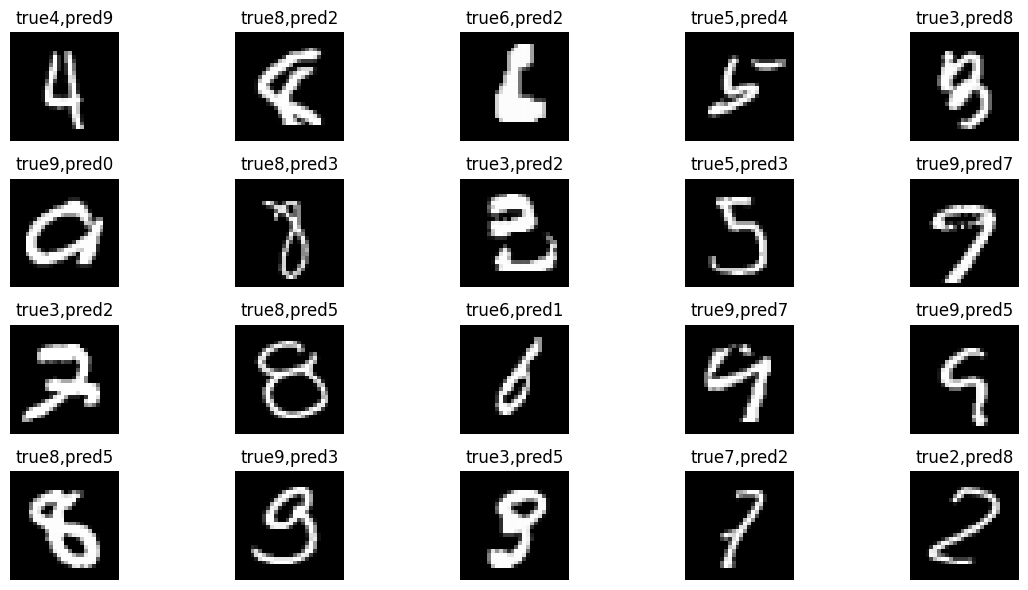

In [22]:
import matplotlib.pyplot as plt
wrong=np.where(y_pred != y_val)[0]
print(len(wrong))
plt.figure(figsize=(12,6))
for i ,idx in enumerate(wrong[:20]):
  plt.subplot(4,5,i+1)
  plt.imshow(x_val[idx],cmap="gray")
  plt.title(f"true{y_val[idx]},pred{y_pred[idx]}")
  plt.axis("off")
plt.tight_layout()
plt.show()

In [23]:
W1,b1,W2,b2=model.get_weights()
print(W1.shape,b1.shape,W2.shape,b2.shape)
x=x_val.reshape(len(x_val),784)
z1=x@W1+b1
a1=np.maximum(0,z1)
z2=a1@W2 +b2
e=np.exp(z2-z2.max(axis=1,keepdims=True))
my_probs=e/e.sum(axis=1,keepdims=True)
print(np.allclose(my_probs,probs,atol=1e-5))


(784, 128) (128,) (128, 10) (10,)
True


In [24]:
x_test_flat=x_test.reshape(len(x_test),784)
test_loss,test_acc=model.evaluate(x_test,y_test)
print(test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9727 - loss: 0.0895
0.9726999998092651
